In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [81]:
#stile grafici
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

In [82]:
df = pd.read_excel("C:\\Users\\chiar\\OneDrive\\Desktop\\Data Visualization\\totx4190.xlsx")

# ANALISI DELLE EMISSIONI DI GAS SERRA (ESCLUSI I 4 MEMO) PER I PAESI EUROPEI + NORVEGIA E ISLANDA
## Unità di misura: indice con base 1990

In [83]:
df['Year'] = df["country"]
df = df.drop(columns=["country"])
df = df.set_index('Year')

In [87]:
print(f"{df.head()}")
print(f"Dimensioni: {df.shape}")

      Austria  Belgium  Bulgaria  Cyprus  Czech Republic  Germany  Denmark  \
Year                                                                         
1990    100.0    100.0     100.0   100.0           100.0    100.0    100.0   
1991    104.6    101.9      81.8   109.0            91.1     96.3    114.9   
1992     96.4    101.5      76.2   116.8            88.1     92.4    106.6   
1993     96.8    100.6      75.5   122.0            85.0     91.7    109.9   
1994     97.1    103.8      71.4   126.5            80.5     90.2    115.3   

      Estonia  Greece  Spain  ...  Latvia  Malta  Netherlands  Norway  Poland  \
Year                          ...                                               
1990    100.0   100.0  100.0  ...   100.0  100.0        100.0   100.0   100.0   
1991     92.9   100.0  102.8  ...    92.7   94.4        103.5    95.4    97.4   
1992     67.6   101.3  106.0  ...    74.4   95.7        103.7    92.4    94.7   
1993     54.0   100.8  102.4  ...    61.2  118.6

### Analisi Missing value

In [41]:
print(f"\nMissing: {df.isnull().sum().sum()} valori ({df.isnull().any().any()})")


Missing: 0 valori (False)


### Statistiche descrittive

In [88]:
print(df.describe())

          Austria     Belgium    Bulgaria      Cyprus  Czech Republic  \
count   34.000000   34.000000   34.000000   34.000000       34.000000   
mean   103.041176   91.747059   63.670588  147.908824       72.767647   
std      6.879972   11.781682   10.108608   18.929444       10.111791   
min     86.300000   67.400000   45.800000  100.000000       52.200000   
25%     99.725000   80.825000   58.175000  139.675000       65.425000   
50%    101.750000   96.550000   61.100000  149.350000       74.300000   
75%    106.625000  101.400000   67.350000  159.775000       76.725000   
max    117.200000  107.700000  100.000000  179.400000      100.000000   

          Germany     Denmark     Estonia      Greece       Spain  ...  \
count   34.000000   34.000000   34.000000   34.000000   34.000000  ...   
mean    77.982353   91.320588   49.747059  105.794118  119.832353  ...   
std     11.255718   20.235519   14.408126   17.992034   17.074023  ...   
min     53.700000   54.200000   27.000000   69

### Valore medio dell'indice per nazione (dal 1990 al 2023)

In [90]:
indice_medio = df.mean().sort_values(ascending=False)
print(indice_medio)

Cyprus            147.908824
Spain             119.832353
Portugal          118.441176
Iceland           118.235294
Ireland           111.767647
Greece            105.794118
Norway            103.147059
Austria           103.041176
Malta             102.494118
Slovenia           98.744118
Italy              96.764706
Finland            93.273529
France             92.823529
Netherlands        92.758824
Belgium            91.747059
Denmark            91.320588
Sweden             87.467647
Luxembourg         86.258824
Poland             85.979412
Croatia            83.294118
Germany            77.982353
Hungary            75.470588
Czech Republic     72.767647
Slovakia           64.891176
Bulgaria           63.670588
Romania            57.688235
Estonia            49.747059
Lithuania          47.755882
Latvia             47.532353
dtype: float64


### Analisi variazioni rispetto al 1990

In [93]:
if 2023 in df.index:
    indice_2023 = df.loc[2023].sort_values()
    variazione_percentuale = (df.loc[2023] - 100).sort_values(ascending=False)
    
    print("\nIndice 2023 (ordinato):")
    print(indice_2023)
    
    print("\nVariazione % rispetto al 1990:")
    print(variazione_percentuale)
    
    print(f"\n--- PAESI CON MAGGIOR RIDUZIONE ---")
    print(variazione_percentuale.head(5))
    
    print(f"\n--- PAESI CON MAGGIOR AUMENTO ---")
    print(variazione_percentuale.tail(5))


Indice 2023 (ordinato):
Estonia            27.0
Lithuania          37.6
Latvia             38.3
Romania            40.5
Bulgaria           45.8
Slovakia           49.1
Czech Republic     52.2
Germany            53.7
Denmark            54.2
Hungary            57.2
Finland            57.2
Luxembourg         60.9
Sweden             62.3
Netherlands        63.9
Belgium            67.4
France             68.9
Greece             69.2
Poland             73.2
Italy              73.6
Slovenia           78.6
Croatia            80.6
Malta              85.5
Austria            86.3
Portugal           90.4
Norway             90.9
Spain              94.2
Ireland            98.6
Iceland           125.3
Cyprus            152.4
Name: 2023, dtype: float64

Variazione % rispetto al 1990:
Cyprus            52.4
Iceland           25.3
Ireland           -1.4
Spain             -5.8
Norway            -9.1
Portugal          -9.6
Austria          -13.7
Malta            -14.5
Croatia          -19.4
Slovenia     

### Analisi rispetto agli obbiettivi climatici

In [94]:
# Calcolo riduzione media UE
if 1990 in df.index and 2023 in df.index:
    indice_medio_ue = df.mean(axis=1)
    riduzione_ue = 100 - indice_medio_ue.loc[2023]
    print(f"Riduzione media UE rispetto al 1990: {riduzione_ue:.2f}%")
    print(f"Indice medio UE 2023: {indice_medio_ue.loc[2023]:.2f}")
    
    # Obiettivo 55% riduzione entro 2030
    obiettivo_2030 = 45  # indice
    print(f"\nObiettivo UE 2030 (riduzione 55%): Indice = {obiettivo_2030}")
    print(f"Gap da colmare: {indice_medio_ue.loc[2023] - obiettivo_2030:.2f} punti indice")

Riduzione media UE rispetto al 1990: 29.83%
Indice medio UE 2023: 70.17

Obiettivo UE 2030 (riduzione 55%): Indice = 45
Gap da colmare: 25.17 punti indice


### Paesi che hanno raggiunto l'obbiettivo

In [96]:
if 2023 in df.index:
    obiettivo_55 = 45  # -55% = indice 45
    
    paesi_obiettivo_55 = df.loc[2023][df.loc[2023] <= obiettivo_55].sort_values()
       
    print(f"\n=== PAESI CHE HANNO RAGGIUNTO -55% (Indice ≤ 45) ===")
    print(f"Numero paesi: {len(paesi_obiettivo_55)}")
    print(paesi_obiettivo_55)


=== PAESI CHE HANNO RAGGIUNTO -55% (Indice ≤ 45) ===
Numero paesi: 4
Estonia      27.0
Lithuania    37.6
Latvia       38.3
Romania      40.5
Name: 2023, dtype: float64


# Grafici

### EU Average Index with Targets

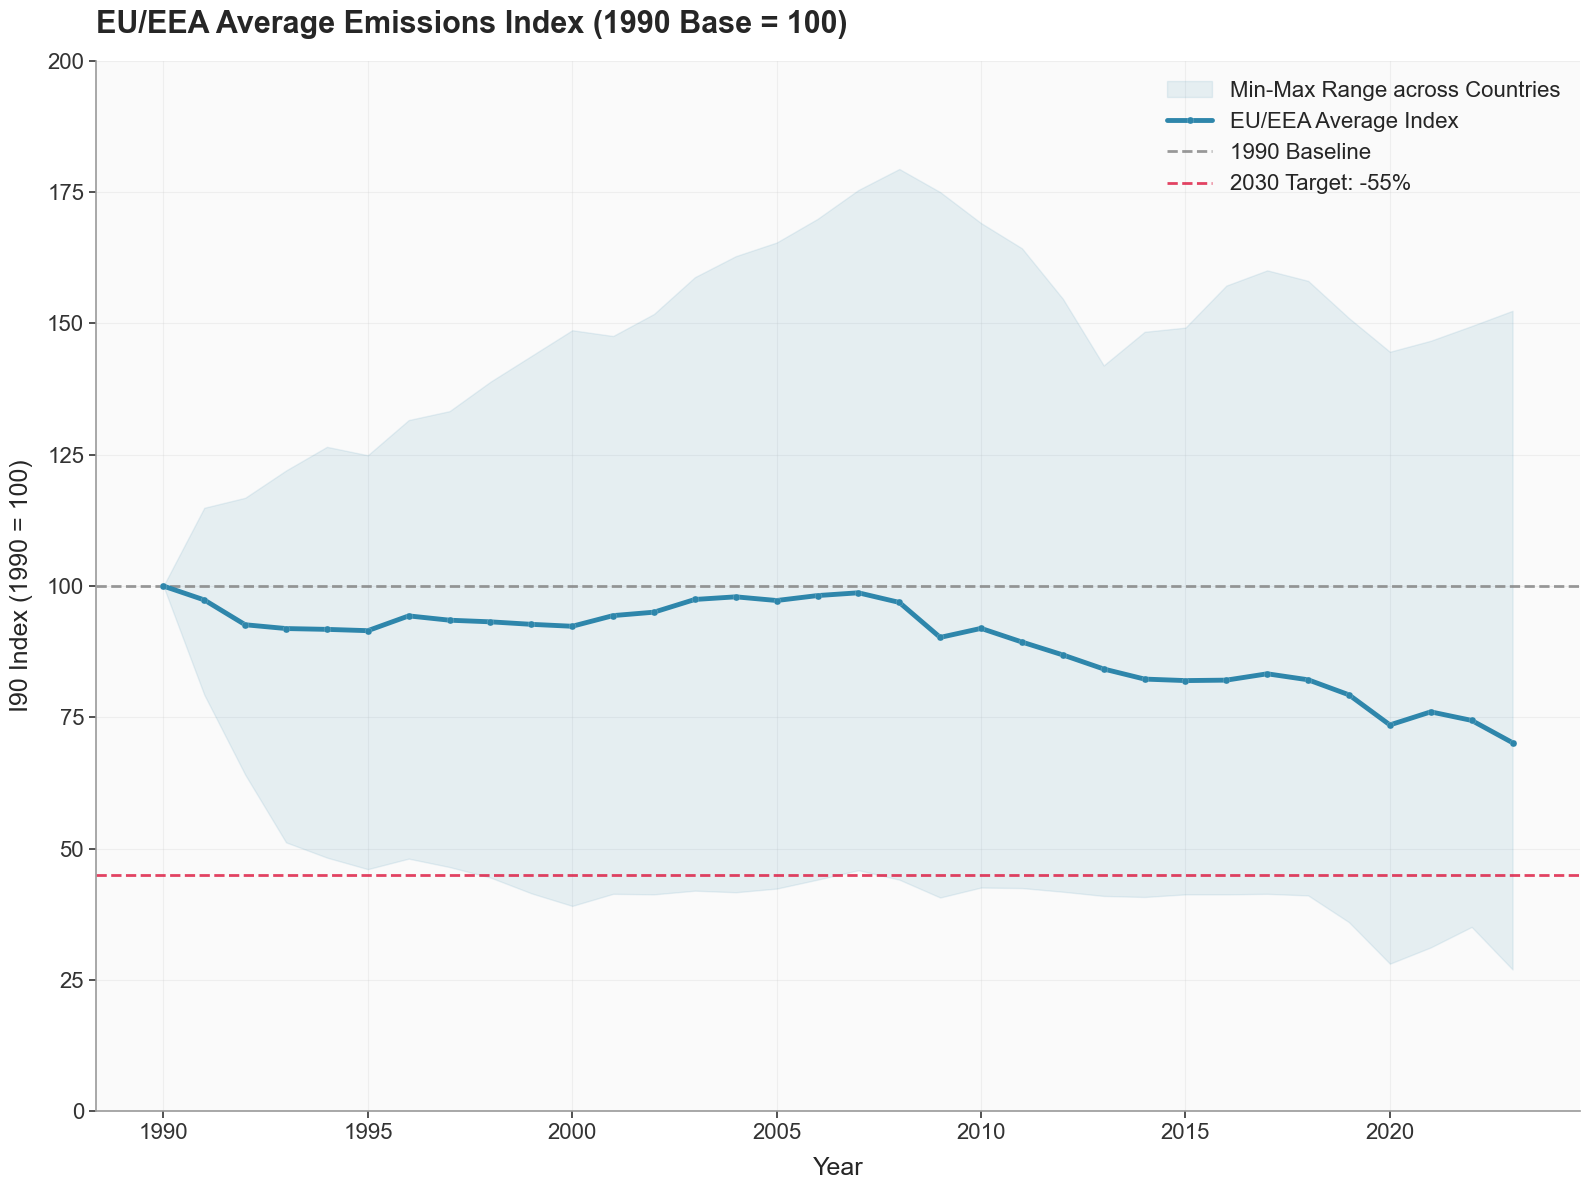

In [ ]:
fig, ax = plt.subplots(figsize=(16, 12))

# colore sfondo (standard utilizzato per tutti i grafici)
ax.set_facecolor("#fafafa")
fig.patch.set_facecolor("white")

average_eu_index = df.mean(axis=1)
max_eu_index = df.max(axis=1)
min_eu_index = df.min(axis=1)

# area di varianza
plt.fill_between(df.index, min_eu_index, max_eu_index, 
                 alpha=0.1, color='#2E86AB', zorder=1,
                 label='Min-Max Range across Countries')

# andamento medio
plt.plot(df.index, average_eu_index, linewidth=3.5, marker='o', 
         markersize=5, label='EU/EEA Average Index', color='#2E86AB', 
         markerfacecolor='#2E86AB', markeredgecolor='white', 
         markeredgewidth=0.1, zorder=3)

# base e obbiettivo
objectives = [
    (100, 'gray', '1990 Baseline', '--', 2),
    (45, '#DC143C', '2030 Target: -55%', '--', 2)
]

for y_val, color, label, style, width in objectives:
    plt.axhline(y=y_val, color=color, linestyle=style, linewidth=width, 
                label=label, alpha=0.8, zorder=2)

# titolo
plt.title('EU/EEA Average Emissions Index (1990 Base = 100)',
          fontsize=22, fontweight='bold', pad=20, loc='left')

# assi
y_min = 0
y_max = 200
plt.ylim(y_min, y_max)

plt.xlabel('Year', fontsize=18, fontweight='medium', labelpad=10)
plt.ylabel('I90 Index (1990 = 100)', fontsize=18, fontweight='medium', labelpad=10)

plt.grid(True, alpha=0.25, color="#cccccc", linestyle='-', linewidth=0.8, zorder=0)

ax.tick_params(colors="#333333", labelsize=16, length=5, width=1.2)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_color("#999999")
    ax.spines[spine].set_linewidth(1.2)

# legenda
plt.legend(loc='upper right', fontsize=16, frameon=True, 
         fancybox=True, framealpha=0,
         edgecolor='#cccccc')

plt.tight_layout()
#plt.savefig('eu_average_index_improved.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()


### Paesi con emissioni più alte rispetto al 1990

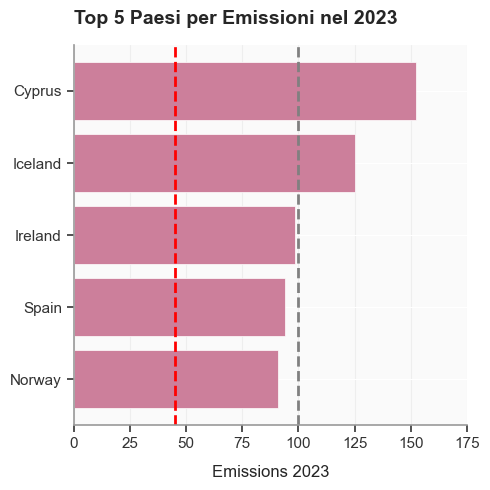

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))

# colore sfondo
ax.set_facecolor("#fafafa")
fig.patch.set_facecolor("white")

if 2023 in df.index:
    emissioni_2023 = df.loc[2023].sort_values(ascending=False)
    top5 = emissioni_2023.head(5)
    
    # barre orizzontali
    plt.barh(range(len(top5)), top5.values, color="#CC7F9B", 
             edgecolor='white', linewidth=0.5)
    
    # assi
    plt.yticks(range(len(top5)), top5.index, fontsize=12)
    plt.xlabel('Emissions 2023', fontsize=12, fontweight='medium', labelpad=10)
    
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_color("#999999")
        ax.spines[spine].set_linewidth(1.2)

    # titolo
    plt.title('Top 5 Paesi per Emissioni nel 2023', 
              fontsize=14, fontweight='bold', pad=15, loc='left')
    
    # valori massimi in alto
    plt.gca().invert_yaxis()
    
    # griglia
    plt.grid(True, alpha=0.25, color="#cccccc", linestyle='-', 
             linewidth=0.8, axis='x', zorder=0)

    ax.tick_params(colors="#333333", labelsize=11, length=5, width=1.2)

    plt.axvline(x=45, color='red', linestyle='--', linewidth=2, label='Obiettivo -55%')
    plt.axvline(x=100, color='gray', linestyle='--', linewidth=2, label='Baseline 1990')

    y_min = 0
    y_max = 175
    plt.xlim(y_min, y_max)

    plt.tight_layout()
    #plt.savefig('top5_paesi_2023.png', dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()

### Paesi con emissioni più basse rispetto al 1990

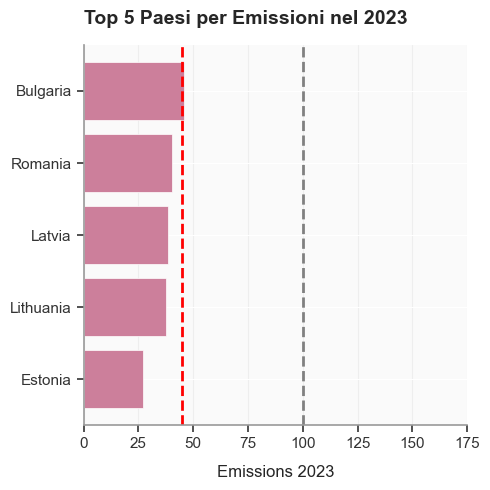

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))

# colore sfondo
ax.set_facecolor("#fafafa")
fig.patch.set_facecolor("white")

if 2023 in df.index:
    emissioni_2023 = df.loc[2023].sort_values(ascending=False)
    top5 = emissioni_2023.tail(5)
    
    # barre orizzontali
    plt.barh(range(len(top5)), top5.values, color="#CC7F9B", 
             edgecolor='white', linewidth=0.5)
    
    # assi
    plt.yticks(range(len(top5)), top5.index, fontsize=12)
    plt.xlabel('Emissions 2023', fontsize=12, fontweight='medium', labelpad=10)

    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_color("#999999")
        ax.spines[spine].set_linewidth(1.2)

    # titolo
    plt.title('Top 5 Paesi per Emissioni nel 2023', 
              fontsize=14, fontweight='bold', pad=15, loc='left')
    
    # valori massimi in alto
    plt.gca().invert_yaxis()
    
    # griglia
    plt.grid(True, alpha=0.25, color="#cccccc", linestyle='-', 
             linewidth=0.8, axis='x', zorder=0)

    ax.tick_params(colors="#333333", labelsize=11, length=5, width=1.2)

    plt.axvline(x=45, color='red', linestyle='--', linewidth=2, label='Obiettivo -55%')
    plt.axvline(x=100, color='gray', linestyle='--', linewidth=2, label='Baseline 1990')

    y_min = 0
    y_max = 175
    plt.xlim(y_min, y_max)

    plt.tight_layout()
    #plt.savefig('top5_paesi_2023.png', dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()

### Classifica paesi 2023 vs 1990

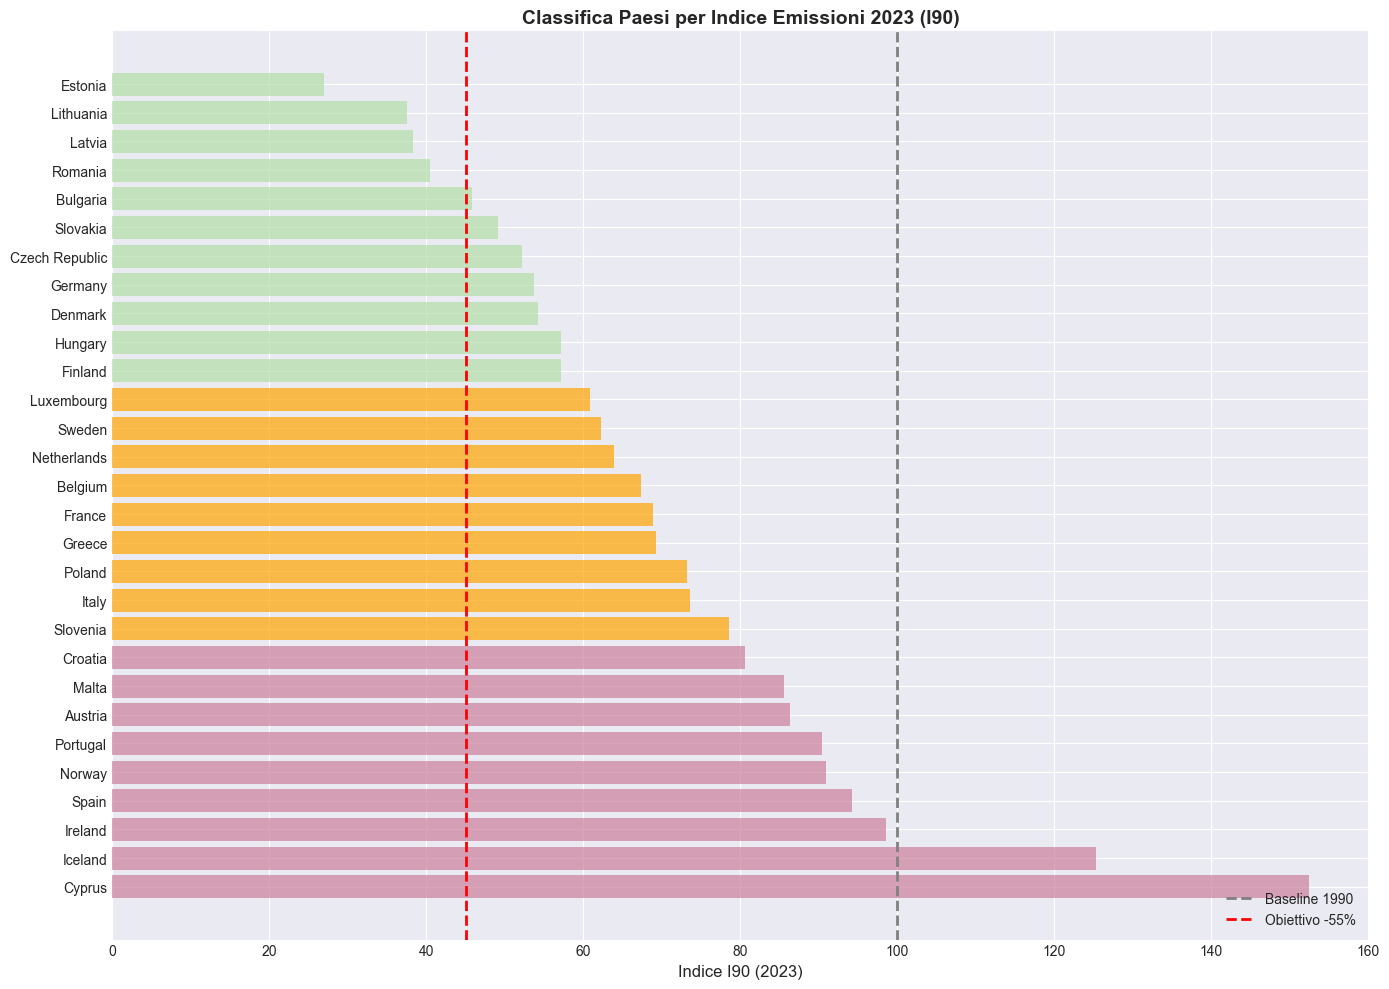

In [ ]:
if 2023 in df.index:
    plt.figure(figsize=(14, 10))
    indice_2023_sorted = df.loc[2023].sort_values()
    colors = ["#B2DEA6" if x <= 60 else 'orange' if x <= 80 else "#CC7F9B" 
              for x in indice_2023_sorted.values]
    
    plt.barh(range(len(indice_2023_sorted)), indice_2023_sorted.values, color=colors, alpha=0.7)
    plt.yticks(range(len(indice_2023_sorted)), indice_2023_sorted.index, fontsize=10)
    plt.axvline(x=100, color='gray', linestyle='--', linewidth=2, label='Baseline 1990')
    plt.axvline(x=45, color='red', linestyle='--', linewidth=2, label='Obiettivo -55%')
    plt.xlabel('Indice I90 (2023)', fontsize=12)
    plt.title('Classifica Paesi per Indice Emissioni 2023 (I90)', 
              fontsize=14, fontweight='bold')
    plt.legend(loc='lower right', fontsize=10)
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.savefig('classifica_paesi_2023.png', dpi=300, bbox_inches='tight')
    plt.show()

### Andamento principali paesi (migliori e peggiori)

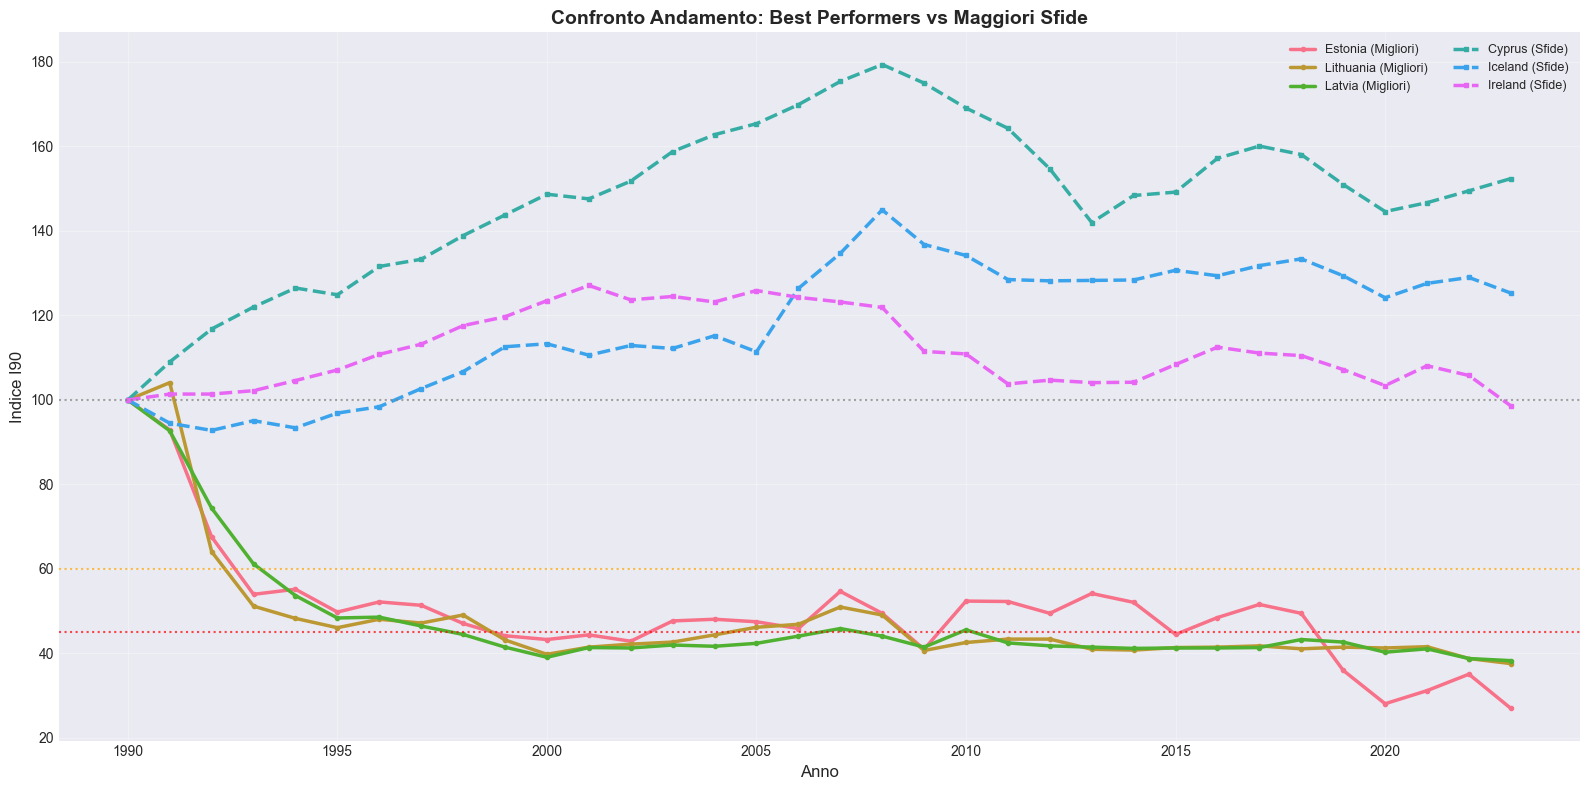

In [ ]:
plt.figure(figsize=(16, 8))

if 2023 in df.index:
    # 3 migliori (riduzione maggiore)
    migliori_3 = df.loc[2023].nsmallest(3).index
    # 3 peggiori (aumento maggiore o minor riduzione)
    peggiori_3 = df.loc[2023].nlargest(3).index
    
    for paese in migliori_3:
        plt.plot(df.index, df[paese], marker='o', markersize=3, 
                label=f'{paese} (Migliori)', linewidth=2.5, linestyle='-')
    
    for paese in peggiori_3:
        plt.plot(df.index, df[paese], marker='s', markersize=3, 
                label=f'{paese} (Sfide)', linewidth=2.5, linestyle='--')

plt.axhline(y=100, color='gray', linestyle=':', linewidth=1.5, alpha=0.7)
plt.axhline(y=60, color='orange', linestyle=':', linewidth=1.5, alpha=0.7)
plt.axhline(y=45, color='red', linestyle=':', linewidth=1.5, alpha=0.7)
plt.title('Confronto Andamento: Best Performers vs Maggiori Sfide', 
          fontsize=14, fontweight='bold')
plt.xlabel('Anno', fontsize=12)
plt.ylabel('Indice I90', fontsize=12)
plt.legend(loc='best', fontsize=9, ncol=2)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('confronto_best_worst.png', dpi=300, bbox_inches='tight')
plt.show()

### Variazione cumulativa rispetto al 1990

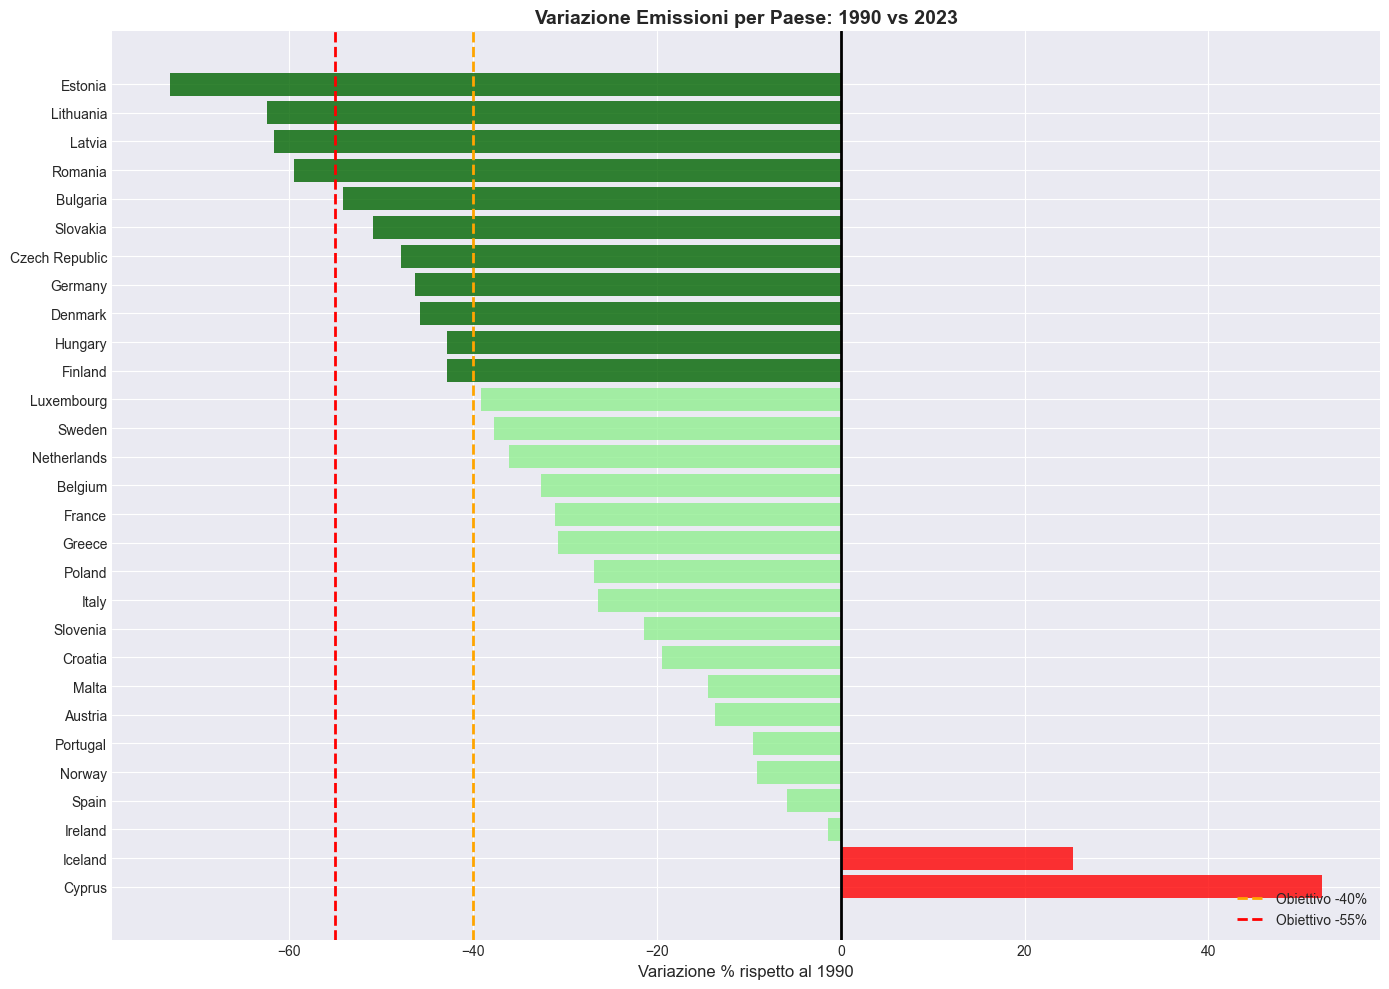

In [ ]:
if 2023 in df.index:
    plt.figure(figsize=(14, 10))
    variazioni = df.loc[2023] - 100
    variazioni_sorted = variazioni.sort_values()
    colors = ['darkgreen' if x <= -40 else 'lightgreen' if x < 0 
              else 'orange' if x < 20 else 'red' for x in variazioni_sorted.values]
    
    plt.barh(range(len(variazioni_sorted)), variazioni_sorted.values, color=colors, alpha=0.8)
    plt.yticks(range(len(variazioni_sorted)), variazioni_sorted.index, fontsize=10)
    plt.axvline(x=0, color='black', linewidth=2)
    plt.axvline(x=-40, color='orange', linestyle='--', linewidth=2, label='Obiettivo -40%')
    plt.axvline(x=-55, color='red', linestyle='--', linewidth=2, label='Obiettivo -55%')
    plt.xlabel('Variazione % rispetto al 1990', fontsize=12)
    plt.title('Variazione Emissioni per Paese: 1990 vs 2023', 
              fontsize=14, fontweight='bold')
    plt.legend(loc='lower right', fontsize=10)
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.savefig('variazione_percentuale_1990_2023.png', dpi=300, bbox_inches='tight')
    plt.show()